# Evaluación Formativa 1 — Análisis exploratorio
## Dataset: *Rain in Australia* (weatherAUS)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello

**Grupo 4:** Jeremmy Díaz Alfaro · Karim Zaid Sánchez · Laura Arenas Kosin

Este notebook sigue el mismo orden del código de ejemplo del profesor (Give Me Some Credit), pero con nuestro dataset.
Por ahora llega hasta la **Figura 3**:

1. Estadística descriptiva (ID1.2): tipos de variables, Tabla 1, calidad de datos, Figura 1 y Figura 2.
2. Estimación puntual e intervalos de confianza (ID1.3): Tabla 2 y Figura 3

La variable objetivo es `RainTomorrow`: si al día siguiente llovió (Yes) o no (No). Semilla fija: `42`.

## 0. Configuración y carga de datos

El archivo `weatherAUS.csv` está en `data/raw/` (descargado de Kaggle). Lo cargamos con la función de `src/carga_datos.py`, que usa ruta relativa.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# buscamos la carpeta del proyecto para poder importar src
raiz = Path.cwd().resolve()
while not (raiz / "src").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.append(str(raiz))

from src.carga_datos import cargar_weather

SEED = 42
np.random.seed(SEED)

# carpeta donde se guardan las figuras del informe
FIGURAS = raiz / "figuras"
FIGURAS.mkdir(exist_ok=True)

df = cargar_weather()
TARGET = "RainTomorrow"
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### Estilo de las figuras
Usamos la misma paleta del ejemplo del profesor: fondo crema, verde azulado para la serie principal, terracota para la clase minoritaria y ocre para las líneas de referencia.

In [2]:
TEAL  = '#2e6b75'   # serie principal
TERRA = '#a35140'   # clase minoritaria / textos de referencia
OCHRE = '#c4862f'   # líneas de referencia (media, mediana)
STEM  = '#bdb3a3'   # tallos de los gráficos lollipop
BG    = '#f6f1ea'   # fondo de los ejes
GRID  = '#ddd5c6'   # líneas de grilla

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200,
    'font.family': 'serif', 'font.size': 10,
    'axes.facecolor': BG, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
})

## 1. Estadística descriptiva (ID1.2)

### 1.1 Tipos de variables y medidas resumen
El dataset tiene 23 columnas: una fecha, la ciudad, cuatro variables de dirección del viento (categóricas), dos variables Yes/No (`RainToday` y el objetivo `RainTomorrow`) y 16 variables numéricas medidas en la estación (temperatura, lluvia, viento, humedad, presión y nubosidad).

In [3]:
tipos = pd.Series({
    'Date': 'Fecha',
    'Location': 'Categórica nominal (49 ciudades)',
    'MinTemp': 'Continua (°C)',
    'MaxTemp': 'Continua (°C)',
    'Rainfall': 'Continua (mm)',
    'Evaporation': 'Continua (mm)',
    'Sunshine': 'Continua (horas de sol)',
    'WindGustDir': 'Categórica nominal (16 direcciones)',
    'WindGustSpeed': 'Continua (km/h)',
    'WindDir9am': 'Categórica nominal (16 direcciones)',
    'WindDir3pm': 'Categórica nominal (16 direcciones)',
    'WindSpeed9am': 'Continua (km/h)',
    'WindSpeed3pm': 'Continua (km/h)',
    'Humidity9am': 'Continua (%)',
    'Humidity3pm': 'Continua (%)',
    'Pressure9am': 'Continua (hPa)',
    'Pressure3pm': 'Continua (hPa)',
    'Cloud9am': 'Discreta ordinal (octas, 0 a 8)',
    'Cloud3pm': 'Discreta ordinal (octas, 0 a 8)',
    'Temp9am': 'Continua (°C)',
    'Temp3pm': 'Continua (°C)',
    'RainToday': 'Binaria (Yes/No)',
    'RainTomorrow': 'Binaria (objetivo)',
}, name='Tipo')
tipos.to_frame()

,Tipo
Date,Fecha
Location,Categórica nominal (49 ciudades)
MinTemp,Continua (°C)
MaxTemp,Continua (°C)
Rainfall,Continua (mm)
Evaporation,Continua (mm)
Sunshine,Continua (horas de sol)
WindGustDir,Categórica nominal (16 direcciones)
WindGustSpeed,Continua (km/h)
WindDir9am,Categórica nominal (16 direcciones)


**Tabla 1.** Media, mediana, desviación estándar, mínimo y máximo de las variables numéricas.

In [4]:
numericas = df.select_dtypes(include='number').columns
desc = df[numericas].describe().T[['mean', '50%', 'std', 'min', 'max']]
desc.columns = ['Media', 'Mediana', 'Desv. est.', 'Mínimo', 'Máximo']
desc.round(2)

,Media,Mediana,Desv. est.,Mínimo,Máximo
MinTemp,12.19,12.0,6.40,-8.5,33.9
MaxTemp,23.22,22.6,7.12,-4.8,48.1
Rainfall,2.36,0.0,8.48,0.0,371.0
Evaporation,5.47,4.8,4.19,0.0,145.0
Sunshine,7.61,8.4,3.79,0.0,14.5
WindGustSpeed,40.04,39.0,13.61,6.0,135.0
WindSpeed9am,14.04,13.0,8.92,0.0,130.0
WindSpeed3pm,18.66,19.0,8.81,0.0,87.0
Humidity9am,68.88,70.0,19.03,0.0,100.0
Humidity3pm,51.54,52.0,20.80,0.0,100.0


Para las variables categóricas no tiene sentido calcular media, así que mostramos la cantidad de categorías, la más frecuente (moda) y cuántas veces aparece.

In [5]:
categoricas = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
resumen_cat = df[categoricas].describe().T[['count', 'unique', 'top', 'freq']]
resumen_cat.columns = ['n (sin nulos)', 'N.º categorías', 'Moda', 'Frecuencia moda']
resumen_cat

,n (sin nulos),N.º categorías,Moda,Frecuencia moda
Location,145460,49,Canberra,3436
WindGustDir,135134,16,W,9915
WindDir9am,134894,16,N,11758
WindDir3pm,141232,16,SE,10838
RainToday,142199,2,No,110319
RainTomorrow,142193,2,No,110316


### 1.2 Calidad de datos
Revisamos el balance del objetivo, los datos faltantes, los duplicados y si hay valores imposibles.

In [6]:
n = len(df)
y = df[TARGET].dropna()
print(f"Días con lluvia al día siguiente : {(y == 'Yes').mean()*100:.1f}%  (sobre {len(y):,} registros con dato)")
print(f"RainTomorrow sin dato            : {df[TARGET].isna().sum():,} ({df[TARGET].isna().mean()*100:.1f}%)")
print(f"Filas duplicadas                 : {df.duplicated().sum():,}")
print(f"Repetidos (misma fecha y ciudad) : {df.duplicated(['Date', 'Location']).sum():,}")

# la nubosidad se mide en octas (0 a 8), así que 9 no debería existir
print(f"Cloud9am = 9                     : {(df['Cloud9am'] == 9).sum()}")
print(f"Cloud3pm = 9                     : {(df['Cloud3pm'] == 9).sum()}")

# valores máximos que llaman la atención
print(f"Lluvia máxima en un día          : {df['Rainfall'].max():.0f} mm")
print(f"Días con algo de lluvia (>0 mm)  : {(df['Rainfall'] > 0).mean()*100:.1f}%")

# ciudades que nunca registran horas de sol
sin_sol = df.groupby('Location')['Sunshine'].apply(lambda s: s.isna().all())
print(f"Ciudades sin ningún dato de Sunshine: {sin_sol.sum()} de {df['Location'].nunique()}")

Días con lluvia al día siguiente : 22.4%  (sobre 142,193 registros con dato)
RainTomorrow sin dato            : 3,267 (2.2%)
Filas duplicadas                 : 0
Repetidos (misma fecha y ciudad) : 0
Cloud9am = 9                     : 2
Cloud3pm = 9                     : 1
Lluvia máxima en un día          : 371 mm
Días con algo de lluvia (>0 mm)  : 35.1%
Ciudades sin ningún dato de Sunshine: 19 de 49


Filas duplicadas                 : 0
Repetidos (misma fecha y ciudad) : 0
Cloud9am = 9                     : 2
Cloud3pm = 9                     : 1
Lluvia máxima en un día          : 371 mm
Días con algo de lluvia (>0 mm)  : 35.1%
Ciudades sin ningún dato de Sunshine: 19 de 49


In [7]:
# chequeo: RainToday es 'Yes' cuando llovió más de 1 mm ese día
ok = df.dropna(subset=['Rainfall', 'RainToday'])
coincide = ((ok['Rainfall'] > 1) == (ok['RainToday'] == 'Yes')).mean()
print(f"RainToday coincide con Rainfall > 1 mm en el {coincide*100:.1f}% de los registros")
assert coincide == 1.0

RainToday coincide con Rainfall > 1 mm en el 100.0% de los registros


### Figura 1 - Variable objetivo y datos faltantes

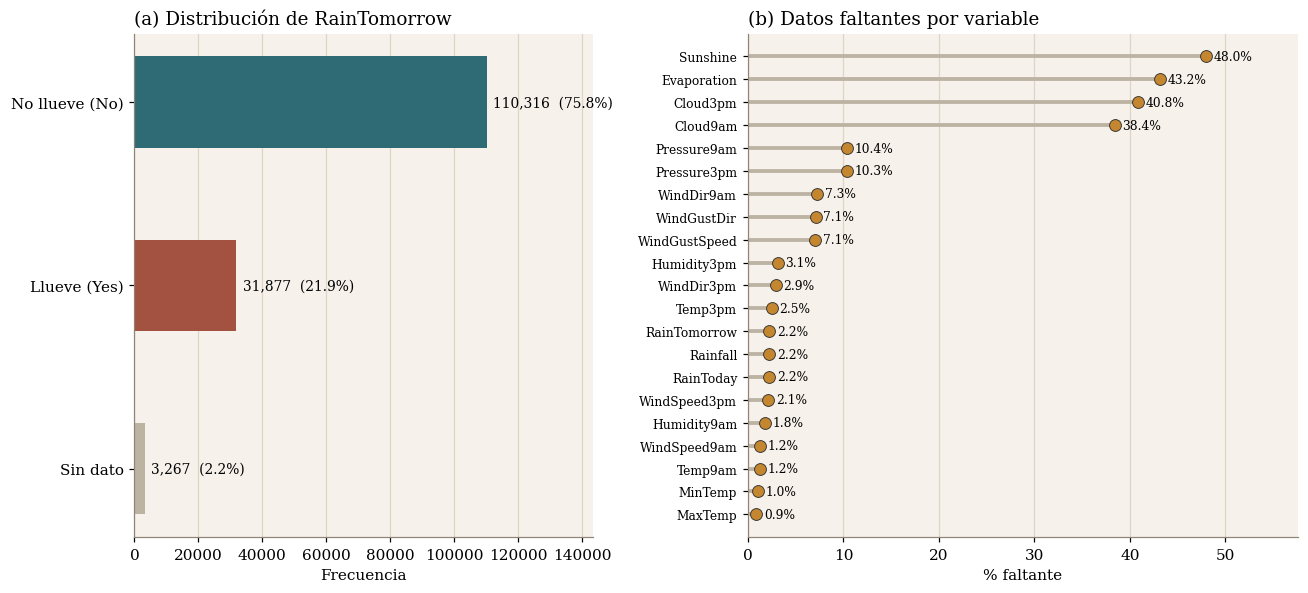

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})

# (a) distribución de la variable objetivo (barras horizontales)
vc = df[TARGET].value_counts(dropna=False)
vc.index = ['No llueve (No)' if v == 'No' else 'Llueve (Yes)' if v == 'Yes' else 'Sin dato' for v in vc.index]
vc = vc.reindex(['No llueve (No)', 'Llueve (Yes)', 'Sin dato'])
ax[0].barh(vc.index, vc.values, color=[TEAL, TERRA, STEM], height=0.5)
ax[0].invert_yaxis()
for i, v in enumerate(vc.values):
    ax[0].text(v + 2000, i, f'{v:,}  ({v/n*100:.1f}%)', va='center', fontsize=9)
ax[0].set_xlim(0, vc.max() * 1.3)
ax[0].set_xlabel('Frecuencia')
ax[0].set_title('(a) Distribución de RainTomorrow')
ax[0].grid(axis='y', visible=False)

# (b) porcentaje de faltantes por variable (lollipop horizontal)
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
pos = np.arange(len(miss))
ax[1].hlines(pos, 0, miss.values, color=STEM, lw=2.5)
ax[1].scatter(miss.values, pos, s=60, color=OCHRE, edgecolor='#333333', linewidth=0.6, zorder=3)
for i, v in enumerate(miss.values):
    ax[1].text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=8)
ax[1].set_yticks(pos)
ax[1].set_yticklabels(miss.index, fontsize=8)
ax[1].invert_yaxis()
ax[1].set_xlim(0, miss.max() * 1.2)
ax[1].set_xlabel('% faltante')
ax[1].set_title('(b) Datos faltantes por variable')
ax[1].grid(axis='y', visible=False)

plt.tight_layout()
plt.savefig(FIGURAS / 'fig_panorama.png', bbox_inches='tight')
plt.show()

In [9]:
print(f"Variables con datos faltantes: {len(miss)} de {df.shape[1]}")
miss.round(1).to_frame('% faltante').head(6)

Variables con datos faltantes: 21 de 23


,% faltante
Sunshine,48.0
Evaporation,43.2
Cloud3pm,40.8
Cloud9am,38.4
Pressure9am,10.4
Pressure3pm,10.3


**Lectura.** El objetivo está desbalanceado: en cerca de 3 de cada 4 días no llueve al día siguiente. Además, casi todas las variables tienen datos faltantes. Las peores son `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am`, con entre 38% y 48% de faltantes. En el caso de `Sunshine`, 19 ciudades no tienen ni un solo dato, o sea que no es un faltante al azar: hay estaciones que simplemente no miden esa variable. No hay filas duplicadas, pero sí aparecen 3 registros con nubosidad 9, que no es un valor válido en octas.

### Figura 2 - Distribución de tres variables representativas
Elegimos una variable casi simétrica (temperatura máxima), una muy asimétrica (lluvia) y una con cola a la derecha (ráfaga de viento). La lluvia se recorta al percentil 99 solo para graficarla; los cálculos usan todos los datos.

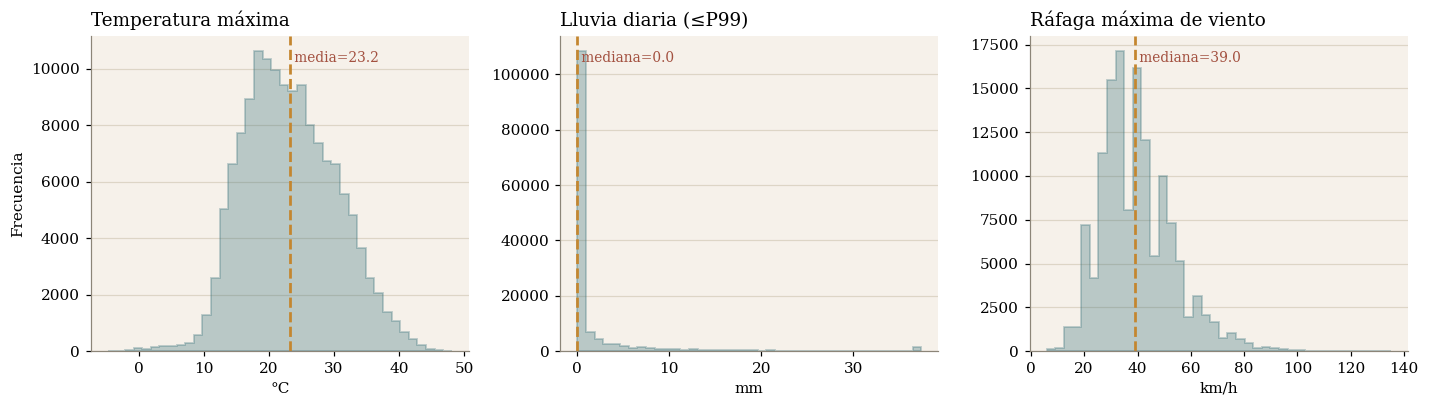

In [10]:
tmax = df['MaxTemp'].dropna()
lluvia = df['Rainfall'].dropna()
racha = df['WindGustSpeed'].dropna()
paneles = [
    (tmax, 'Temperatura máxima', '°C', 'media', tmax.mean()),
    (lluvia.clip(upper=lluvia.quantile(0.99)), 'Lluvia diaria (≤P99)', 'mm', 'mediana', lluvia.median()),
    (racha, 'Ráfaga máxima de viento', 'km/h', 'mediana', racha.median()),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (x, titulo, xlab, nombre, ref) in zip(axes, paneles):
    ax.hist(x, bins=40, histtype='stepfilled', color=TEAL, alpha=0.3,
            edgecolor=TEAL, linewidth=1.2)
    ax.axvline(ref, color=OCHRE, ls='--', lw=1.8)
    ax.text(ref, ax.get_ylim()[1] * 0.93, f' {nombre}={ref:,.1f}', color=TERRA, fontsize=9, va='center')
    ax.set_title(titulo)
    ax.set_xlabel(xlab)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig(FIGURAS / 'fig_distribuciones.png', bbox_inches='tight')
plt.show()

In [11]:
# media vs mediana y asimetría de las tres variables
pd.DataFrame({
    'Media': [tmax.mean(), lluvia.mean(), racha.mean()],
    'Mediana': [tmax.median(), lluvia.median(), racha.median()],
    'Asimetría': [tmax.skew(), lluvia.skew(), racha.skew()],
}, index=['MaxTemp', 'Rainfall', 'WindGustSpeed']).round(2)

,Media,Mediana,Asimetría
MaxTemp,23.22,22.6,0.22
Rainfall,2.36,0.0,9.84
WindGustSpeed,40.04,39.0,0.87


**Lectura.** La temperatura máxima tiene una forma casi simétrica, con la media y la mediana muy parecidas. La lluvia es muy distinta: la mediana es 0 porque en la mayoría de los días no llueve nada, y los pocos días con lluvia forman una cola muy larga hacia la derecha (hasta 371 mm). Por eso para la lluvia conviene usar la mediana y no la media. La ráfaga de viento se concentra entre 30 y 50 km/h y también tiene algo de cola hacia la derecha, aunque bastante menos que la lluvia.

## 2. Estimación puntual e intervalos de confianza (ID1.3)

Estimamos parámetros poblacionales con un nivel de confianza del 95%. Igual que en el ejemplo del profesor, usamos el intervalo basado en la aproximación normal (método de Wald), que el Teorema Central del Límite justifica por el gran tamaño de la muestra:

- Media: $\bar{x} \pm z_{0.975}\,\dfrac{s}{\sqrt{n}}$
- Proporción: $\hat{p} \pm z_{0.975}\sqrt{\dfrac{\hat{p}(1-\hat{p})}{n}}$

Elegimos parámetros ligados al problema de decisión: la **proporción de días con lluvia al día siguiente** (el parámetro central) y la **media** de tres variables. Son una casi simétrica (`MaxTemp`), una muy asimétrica (`Rainfall`) y una muy relacionada con la lluvia (`Humidity3pm`). Cada intervalo se calcula con los registros que tienen dato en esa variable.

In [12]:
from scipy import stats

z = stats.norm.ppf(0.975)   # 1.96

def ic_media(x):
    x = pd.Series(x).dropna()
    m = x.mean()
    se = x.std(ddof=1) / np.sqrt(len(x))
    return m, m - z*se, m + z*se, len(x)

def ic_prop(k, n):
    p = k / n
    se = np.sqrt(p*(1 - p) / n)
    return p, p - z*se, p + z*se

filas = []
for col, nombre in [('MaxTemp', 'Temperatura máxima media (°C)'),
                    ('Rainfall', 'Lluvia diaria media (mm)'),
                    ('Humidity3pm', 'Humedad media a las 3 pm (%)')]:
    m, lo, hi, nn = ic_media(df[col])
    filas.append([nombre, m, lo, hi, nn])

y = df[TARGET].dropna()
p, lo, hi = ic_prop((y == 'Yes').sum(), len(y))
filas.append(['Proporción de días con lluvia al día siguiente', p, lo, hi, len(y)])

tabla2 = pd.DataFrame(filas, columns=['Parámetro', 'Estimación', 'IC95% inf', 'IC95% sup', 'n']).set_index('Parámetro')
tabla2.round(4)

,Estimación,IC95% inf,IC95% sup,n
Parámetro,,,,
Temperatura máxima media (°C),23.2213,23.1846,23.2581,144199
Lluvia diaria media (mm),2.3609,2.3169,2.4050,142199
Humedad media a las 3 pm (%),51.5391,51.4306,51.6477,140953
Proporción de días con lluvia al día siguiente,0.2242,0.2220,0.2263,142193


**Tabla 2.** Estimación puntual e intervalos de confianza al 95%.

Para que la estimación sirva a la decisión, estimamos también la proporción de lluvia al día siguiente **según si llovió hoy** (`RainToday`).

In [13]:
sub = df.dropna(subset=[TARGET, 'RainToday'])
filas = []
for grupo, g in sub.groupby('RainToday'):
    k, nn = (g[TARGET] == 'Yes').sum(), len(g)
    p, lo, hi = ic_prop(k, nn)
    filas.append([f'Hoy llovió = {grupo}', p, lo, hi, nn])

p, lo, hi = ic_prop((y == 'Yes').sum(), len(y))
filas.append(['Global', p, lo, hi, len(y)])

ic_cond = pd.DataFrame(filas, columns=['Grupo', 'Proporción', 'IC95% inf', 'IC95% sup', 'n']).set_index('Grupo')
ic_cond.round(4)

,Proporción,IC95% inf,IC95% sup,n
Grupo,,,,
Hoy llovió = No,0.1519,0.1497,0.1540,109332
Hoy llovió = Yes,0.4641,0.4585,0.4696,31455
Global,0.2242,0.2220,0.2263,142193


### Figura 3 - Probabilidad de lluvia al día siguiente con su intervalo de confianza

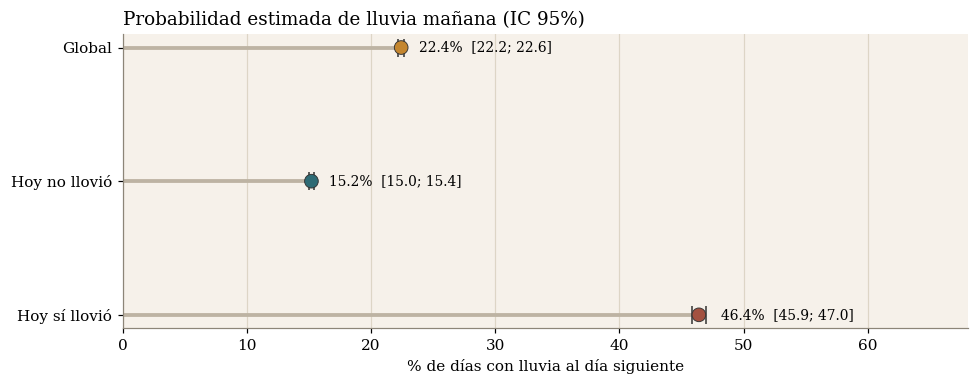

In [14]:
orden = ['Global', 'Hoy llovió = No', 'Hoy llovió = Yes']
d = ic_cond.loc[orden] * [100, 100, 100, 1]   # proporción y límites en %
colores = [OCHRE, TEAL, TERRA]
pos = np.arange(len(d))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hlines(pos, 0, d['Proporción'], color=STEM, lw=2.5)
ax.errorbar(d['Proporción'], pos,
            xerr=[d['Proporción'] - d['IC95% inf'], d['IC95% sup'] - d['Proporción']],
            fmt='none', ecolor='#333333', capsize=6, lw=1.2, zorder=4)
ax.scatter(d['Proporción'], pos, s=80, color=colores, edgecolor='#333333', linewidth=0.6, zorder=5)
for i, (pp, lo, hi) in enumerate(d[['Proporción', 'IC95% inf', 'IC95% sup']].values):
    ax.text(hi + 1.2, i, f'{pp:.1f}%  [{lo:.1f}; {hi:.1f}]', va='center', fontsize=9)
ax.set_yticks(pos)
ax.set_yticklabels(['Global', 'Hoy no llovió', 'Hoy sí llovió'])
ax.invert_yaxis()
ax.set_xlim(0, d['IC95% sup'].max() * 1.45)
ax.set_xlabel('% de días con lluvia al día siguiente')
ax.set_title('Probabilidad estimada de lluvia mañana (IC 95%)')
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.savefig(FIGURAS / 'fig_intervalos.png', bbox_inches='tight')
plt.show()

**Lectura.** Todos los intervalos son muy estrechos. Es lo esperable con más de 140.000 registros: el error estándar se reduce con $\sqrt{n}$.

- **Lluvia al día siguiente.** Con un 95% de confianza, la proporción poblacional de días con lluvia al día siguiente está entre **22,20% y 22,63%** (estimación puntual 22,42%). Es decir, cerca de 1 de cada 4,5 días. Este valor es la "línea base" contra la cual habrá que comparar cualquier modelo: uno que siempre prediga "no llueve" acierta cerca del 78% de las veces sin aprender nada.
- **Temperatura máxima.** La media está entre 23,18 y 23,26 °C. Como la variable es casi simétrica, la media representa bien a un día típico.
- **Lluvia diaria.** La media está entre 2,32 y 2,40 mm, pero la mediana es 0 mm. La media no describe un día típico: la empujan unos pocos días de lluvia muy intensa. Aun así, el intervalo es válido. Con este $n$, el Teorema Central del Límite asegura que la *media muestral* se distribuye de forma aproximadamente normal, aunque la variable original no lo sea.
- **Humedad a las 3 pm.** La media está entre 51,43% y 51,65%.

**Vínculo con la decisión.** La Figura 3 muestra que la estimación cambia mucho según lo que pasó hoy:

- Si hoy llovió, la probabilidad de lluvia mañana es **46,4%** (IC 95%: 45,9%–47,0%).
- Si no llovió, baja a **15,2%** (IC 95%: 15,0%–15,4%).

Los intervalos de los dos grupos no se superponen, lo que indica que la diferencia no se debe al azar del muestreo (lo pondremos a prueba formalmente en la sección de pruebas de hipótesis). Para quien decide, por ejemplo si conviene cancelar una actividad al aire libre, saber si hoy llovió triplica la probabilidad estimada de lluvia mañana. Eso es mucho más útil que la tasa global. Los grupos suman 140.787 registros, algo menos que el total, porque 1.406 días tienen dato de `RainTomorrow` pero no de `RainToday`.

**Precaución.** Las fórmulas suponen observaciones independientes. Aquí son días consecutivos en las mismas 49 ciudades, y el clima de un día se parece al del día siguiente. Por eso la información "real" es algo menor que $n$, y los intervalos probablemente son algo más angostos de lo que deberían. No cambia las conclusiones, pero conviene tenerlo presente.